# How similar is SARS-Cov-2 to other viruses?

Evolution is the process by which different living organisms are believed to have developed from earlier forms during the earth's history. The main component that evolves through time is the DNA which is passed on to the next generation. Genetic mutations, variation, and recombination are processes that modify DNA and cause variation in the population. The main drivers of evolution are natural selection and genetic drift that act on this variation. Through time, some characteristics become more common or rare in the population resulting in a change in heritable ones arising over successive generations.

Even though we do not consider viruses to be *living* organisms, they are still subject to evolution. Their genetic material undergoes the same transformations and selection, resulting in new variants and types of viruses.

<div>
    <img src="https://upload.wikimedia.org/wikipedia/commons/thumb/7/70/Phylogenetic_tree.svg/800px-Phylogenetic_tree.svg.png" width="500">
</div>

Image source: [Wikipedia](https://en.wikipedia.org/wiki/File:Phylogenetic_tree.svg)

Comparing the characteristics of different organisms allows us to estimate their evolutionary distance. We use genetic material as a proxy for these characteristics. We estimate evolutionary distance as the number of transformation events that would occur for one organism to become genetically identical. In practice, this means aligning genetic sequences and observing the number of transformation events. Performing multiple sequence alignment and calculating pairwise distances gives us a distance matrix.

One way of presenting the evolutionary distance between organisms is with a phylogenetic tree. Similar organisms are connected via their common ancestor, even though we do not have genetic data to prove their existence. However, these common ancestors likely existed in the past due to evolution. The most common algorithms for building phylogenetic trees are the UPGMA and Neighbor-Joining algorithms. Many frequentist and Bayesian variations of these are also available online.

Once we know the evolution of the virus, we can expand our knowledge about similar viruses to our virus of interest. Our task is implementing the neighbor-joining method, a plotting function, and constructing a phylogenetic tree of coronaviruses. In the last problem, we will see how recombination can seemingly contradict the flow of evolution.

#### Please ensure each answer is completed in the single cell of the notebook immediately following the question, and that all answers are in ```markdown``` format.

Once you have completed the notebook, make sure you save it and submit it via Moodle.

All questions are worth between 1 and 10 marks. There are a total of *40 marks* available in this workbook. There is one extra bonus problem for *10 marks*. 
  
Total notebook marks will be scaled to a **course mark out of 10** to contribute to your course total.

In [60]:
import numpy as np
import pandas as pd
from Bio import Entrez

In [61]:
# In order to import from the python file without hassle, we add the current
# directory to the python path
import sys; sys.path.append(".")

Let's let the nice folks at NCBI know who we are.

In [62]:
Entrez.email = "z5498942@student.unsw.edu.au"

## Problem 1: Neighbor joining implementation

**Task:** Use the template `neighbor_joining` function in the file `helper_functions.py` and implement the neighbor-joining (NJ) algorithm for agglomerative phylogenetic clustering. Your implementation should return a `Node` object to construct a tree structure and return a root Node. Use provided classes and add code where needed. Stick to the provided structure and test your solution with added unit tests. Provided unit tests do not test the correctness of your implementation but only the structure of your output.

**Implementation requirement:** In theory, the neighbor-joining algorithm results in an unrooted tree. But for plotting and later rooting the tree, your implementation should return a root node. In the last iteration of the NJ, the algorithm joins the final two nodes by creating a root node and setting the distance to each of the remaining nodes as half of the distance between them.

(Optional) In problem 2, you will be implementing a plotting function for a phylogenetic tree. For easier visual comparison of the dendrograms, you can follow instructions in the function docstring to handle node additions and tie-breaks. Even if you handle tie-breaks differently, your implementation will be valid.

**[9 points]**

Answer the following question about the neighbour joining algorithm:
- What is one of the main differences of the neighbour joining algorithm compared to UPGMA? 

Store your answers in the `algorithm_diff` variable.

**[1 points]**.

In [63]:
algorithm_diff = """
What is one of the main differences of the neighbour joining algorithm compared to UPGMA? 

UPGMA assumes a molecular clock of all lineages evolve at the same constant rate. Therefore, it produces an
ultrametric rooted tree in which every leaf is equally far from the root. On the other hand, neighbor joining makes no
molecular-clock assumption. Neighbor joining joins the pair that minimises the Q-criterion, which corrects each pairwise
distance for how far the two taxa are from all the others which is known as net divergence, and it allows different
branch lengths for each leaf which makes it more accurate when evolutionary rates differ between
lineages, and it returns an unrooted tree that must be rooted afterwards.

"""

In [64]:
from helper_functions import neighbor_joining 
from helper_functions import Node 

## Problem 2: Plotting a phylogenetic tree

**Task:**
Use the template `plot_nj_tree` function in the file `helper_functions.py` to write a plotting function using the `matplotlib` library.
The only limitation is to use the template function and two required inputs. How you position a dendrogram, colour the plot, labels and everything else is up to you.

Leaves in a dendrogram are connected via horizontal and vertical lines. Horizontal lines represent genetic distance, while vertical ones present divergence of the last common ancestor. Below is an example of a dendrogram. Leaves do not align on a vertical line as with hierarchical clustering.

<div>
    <img src="https://upload.wikimedia.org/wikipedia/commons/d/dd/Phylogenetic_tree_of_coronaviruses.jpg" width="500">
</div>

*(Patrick C. Y. Woo, Yi Huang, Susanna K. P. Lau, and Kwok-Yung Yuen, [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/deed.en) )*

Test your implementation to our provided unit tests by comparing your output plot to the ground truth in `tests/test_plotting_dendrogram.png`. Write your own tests as well.

**[10 points]**

In [65]:
from helper_functions import plot_nj_tree

## Problem 3: Phylogenetic analysis of coronavirus

You obtained 31 aligned sequences of different coronaviruses collected at multiple time points worldwide. We used the Clustal algorithm to provide you with a multiple sequence alignment (MSA) file in `data/clustal_MSA_coronavirus.fasta`. Each entry has a form `name|accession`.

We will use Hamming distance to calculate genetic distance from pairwise sequence alignment. This naive approach estimates the distance by counting the number of mismatches in the alignment. For example, alignment *"ATC"* and *"ATT"* will have a distance of 1 while *"AT-C"* and *"CTTC"* will have a distance of 2. There are more sophisticated approaches to evolutionary distance estimation, but for our use case, Hamming distance will suffice.

Plot a phylogenetic tree of coronaviruses using your implementation of `neighbor_joining` and `plot_nj_tree`.
Compare your results to the ones found on [Wikipedia](https://en.wikipedia.org/wiki/Coronavirus). Note that three additional viruses in our alignment file do not appear in the figure.

You might notice your figure differs from the one on Wikipedia. Neighbor-joining results in an unrooted or poorly rooted tree at best. Biologists developed a clever approach to determine the root of a neighbor-joining tree by including one distant relative species in the alignment, called the outgroup. In the course of evolution, a distance relative diverged first. We can determine the midpoint between the outgroup and the rest of the phylogenetic tree as a root. This approach proclaims the root node as the last common ancestor between all species in the tree. We will be using the *Breda virus* as an outgroup.

Order in a dendrogram can give an impression of a nicer plot. We can achieve this by setting the left child as the one with fewer leaf nodes in a subtree.

As a final step, fetch NCBI annotations to determine their coronavirus group. Present those groupings on your figure with colors.

**Task:** Plot the most informative phylogenetic tree by iteratively improving your implementation.

**a)** Calculate pairwise distances of aligned sequences using Hamming distance.
Construct and plot the phylogeny dendrogram using your implementations of neighbor-joining and plotting algorithm in `helper_functions`. **[4 points]**

**b)** Reroot the tree using the provided `reroot_tree` function in the `helper_function`. Use it to reroot a tree using the *Breda virus* as an outgroup. You have to fetch an outgroup from the tree first, and then use the reroot function. If you added any other relational parameters to your `Node` class, make sure you adjust the function. **[+1 points]**

**c)** Implement `sort_children_by_leaves` function in the `helper_function`. Use it to sort child nodes by assigning a left child to the one with fewer leaf nodes in their subtree. **[+1 points]**

**d)** Use color and labeling to show four major groups of coronaviruses. You can find the type of coronavirus in the NCBI annotations under the *taxonomy* field. **[+1 points]**

Save your final figure as `problem3.svg`. Make sure you save the figure using `plt.savefig('problem3.svg')` to ensure the correct format.

**[7 points in total]**

Then answer the following questions about the phylogenetic tree you have just drawn:
- To which group does SARS-CoV-2 belong? Answer using only the group name.
- Which of the following organisms would still be a valid outgroup in our case, and why?
  - Munia coronavirus HKU13 
  - Transmissible gastroenteritis coronavirus (TGEV)
  - Turkey coronavirus (TCoV) 
- As described above, we used an outgroup to root our tree. Another way to root a tree is through "Midpoint rooting", where the root is positioned at the midpoint between the two longest branches. What assumption needs to hold for this approach to make sense? 

Save your answers in the variables `sars_cov_2_group`, `valid_outgroup_choice` and `phylogenetic_midroot` respectively.

**[3 points]**

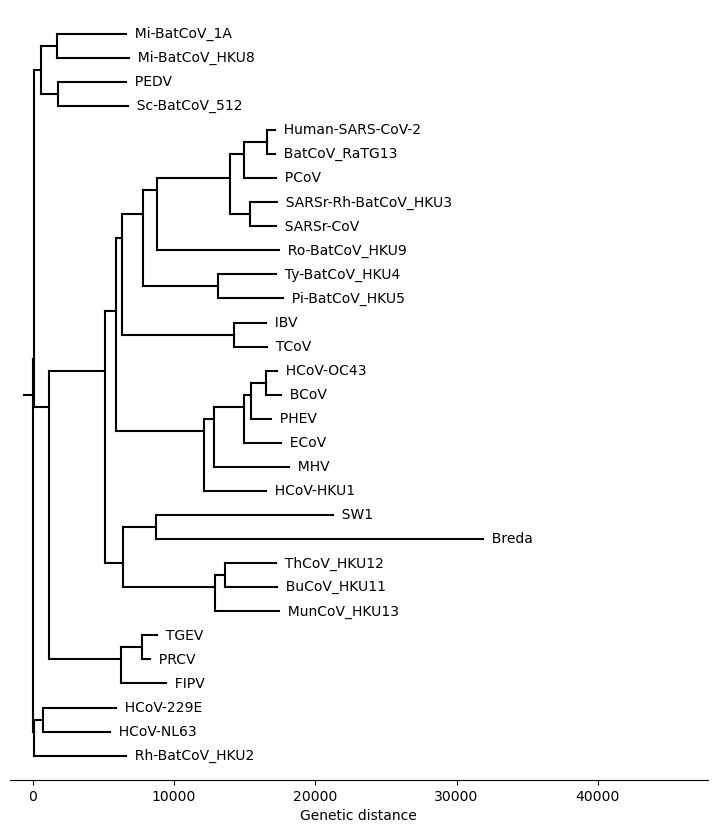

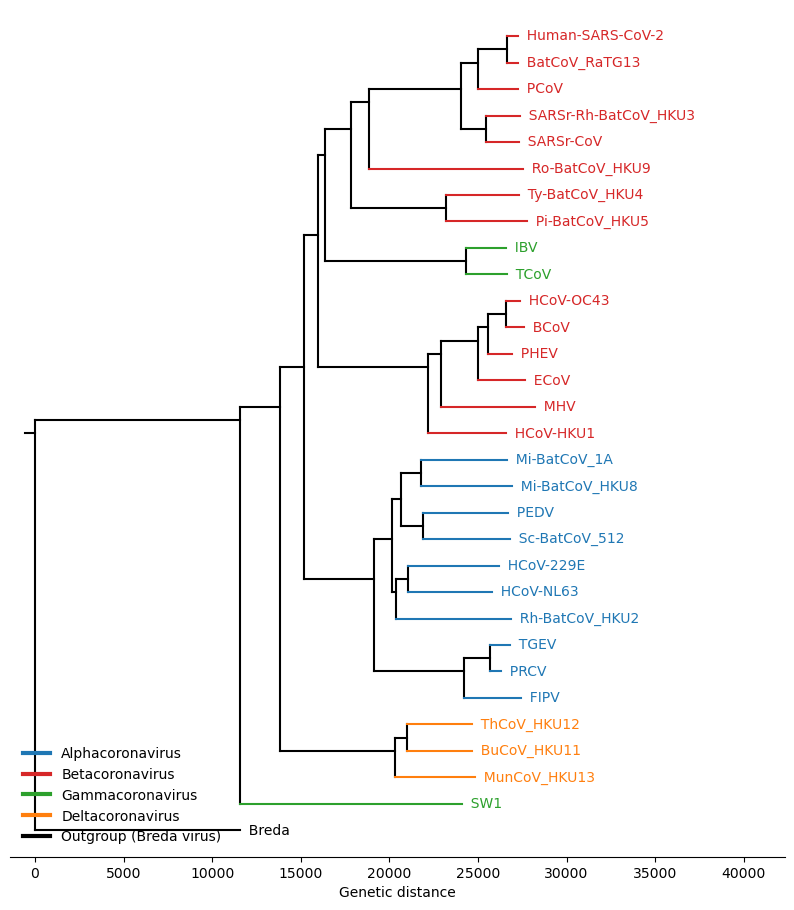

In [66]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from helper_functions import neighbor_joining, plot_nj_tree, reroot_tree, sort_children_by_leaves

# Read the alignment
def read_fasta(path):
    seqs, key = {}, None
    for line in open(path):
        line = line.strip()
        if line.startswith(">"):
            key = line[1:]; seqs[key] = []
        elif key:
            seqs[key].append(line)
    return {k: "".join(v).upper() for k, v in seqs.items()}

aln = read_fasta("data/clustal_MSA_coronavirus.fasta")
labels = [k.split("|")[0] for k in aln]
arr = np.array([list(s) for s in aln.values()])

# a) Hamming distances, neighbor-joining tree and plot
n = len(labels)
D = np.zeros((n, n))
for i in range(n):
    for j in range(i + 1, n):
        D[i, j] = D[j, i] = (arr[i] != arr[j]).sum()

tree = neighbor_joining(D, labels)
fig, ax = plt.subplots(figsize=(9, 10))
plot_nj_tree(tree, ax=ax)
plt.show()

# b) reroot with Breda virus as the outgroup
def find_node(t, name):
    if t is None: return None
    return t if t.name == name else (find_node(t.left, name) or find_node(t.right, name))

rooted = reroot_tree(tree, find_node(tree, "Breda"))

# c) child with fewer leaves on the left
sort_children_by_leaves(rooted)

# d) colour the coronavirus groups
group_of = {}
for l in "FIPV PRCV TGEV Sc-BatCoV_512 PEDV Mi-BatCoV_HKU8 Mi-BatCoV_1A Rh-BatCoV_HKU2 HCoV-NL63 HCoV-229E".split(): group_of[l] = "Alphacoronavirus"
for l in ("MHV HCoV-HKU1 ECoV BCoV HCoV-OC43 PHEV Pi-BatCoV_HKU5 Ty-BatCoV_HKU4 Ro-BatCoV_HKU9 "
          "SARSr-CoV SARSr-Rh-BatCoV_HKU3 PCoV BatCoV_RaTG13 Human-SARS-CoV-2").split(): group_of[l] = "Betacoronavirus"
for l in "SW1 TCoV IBV".split(): group_of[l] = "Gammacoronavirus"
for l in "MunCoV_HKU13 BuCoV_HKU11 ThCoV_HKU12".split(): group_of[l] = "Deltacoronavirus"
group_of["Breda"] = "Outgroup (Breda virus)"
cmap = {"Alphacoronavirus": "tab:blue", "Betacoronavirus": "tab:red", "Gammacoronavirus": "tab:green",
        "Deltacoronavirus": "tab:orange", "Outgroup (Breda virus)": "k"}
colors = {l: cmap[group_of[l]] for l in labels}

fig, ax = plt.subplots(figsize=(10, 11))
plot_nj_tree(rooted, ax=ax, colors=colors)
ax.legend(handles=[Line2D([], [], color=c, lw=3, label=g) for g, c in cmap.items()],
          loc="lower left", frameon=False)
plt.savefig("problem3.svg", bbox_inches="tight")
plt.savefig("problem3.png", dpi=200, bbox_inches="tight")
plt.show()

In [67]:
sars_cov_2_group = """To which group does SARS-CoV-2 belong? Answer using only the group name.

Betacoronavirus

"""

In [68]:
valid_outgroup_choice = """Which of the following organisms would still be a valid outgroup in our case, and why?

Munia coronavirus HKU13 which is a Deltacoronavirus.

An outgroup must have diverged before the common ancestor of the in-group so it has to lie outside the group
being studied rather than nested inside it. TGEV is an Alphacoronavirus that clusters with FIPV and PRCV among the other
alphacoronaviruses so it is nested inside the in-group and cannot be an outgroup. Turkey coronavirus also known as TCoV is a
Gammacoronavirus that groups with IBV therefore it is also embedded among the other viruses. On the other hand, Munia HKU13 belongs to the
Deltacoronavirus genus which branches off deep in the tree which is also far from the mammalian alpha and beta viruses so it
is the most distant of the three and the best choice. All in all, I can conclude that Breda virus remains the outgroup for the full four-genus tree.

"""

In [69]:
phylogenetic_midroot = """What assumption needs to hold for the midpoint rooting approach to make sense? 

Midpoint rooting assumes an approximately constant evolutionary rate
across lineages, known as a molecular clock. Under this assumption,
genetic distance is approximately proportional to elapsed evolutionary
time, so the midpoint of the longest path between two tips can provide
an estimate of the root position.

"""

## Problem 4: Recombination

We tend to think of evolution as a hierarchical process: we have some common ancestor that split into several sub-species through a series of random mutations. However, nothing is that straightforward in biology. There have been well-documented cases of horizontal gene transfer in nature where organisms swap entire chunks of DNA with each other. In viruses, something similar can happen as well. When a cell is infected with multiple virions (potentially different strains of the same virus), a *recombination event* can occur. Recombination occurs during the DNA copying process when, for whatever reason, the copier swaps out the virus template midway with a different template. For instance, we could start copying virus A, and then midway, the copier will switch to virus B, effectively resulting in new virus DNA that has DNA from both viruses A and B.

During the start of the global pandemic, there was much confusion about the origins of SARS-CoV-2. We initially thought it came from bats. Then, at some point, people noticed that a critical piece of the spike protein -- the receptor binding domain (RBD) -- was more similar to the sequence of pangolin coronaviruses. This evidence points to recombination. Before the virus jumped to humans, there must have been some host infected with both the Bat RaTG13 coronavirus and the Pangolin coronavirus where this recombination happened.

In this problem, we will look at the spike protein, look at the receptor binding domain, and check this evidence for recombination ourselves.

**Task**:
Find the spike proteins of the three viruses and align the sequences with each other using your global alignment implementation from the previous assignment. Since we're comparing the differences between the bat and pangolin coronaviruses to the human virus, we only need to compute two alignments: human to bat and human to pangolin. We will then compare the differences between the two alignments. Find the RBD of SARS-CoV-2  using the [NCBI graphical view of the SARS-CoV-2 genome](https://www.ncbi.nlm.nih.gov/projects/sviewer/?id=NC_045512&tracks=[key:sequence_track,name:Sequence,display_name:Sequence,id:STD649220238,annots:Sequence,ShowLabel:false,ColorGaps:false,shown:true,order:1][key:gene_model_track,name:Genes,display_name:Genes,id:STD3194982005,annots:Unnamed,Options:ShowAllButGenes,CDSProductFeats:true,NtRuler:true,AaRuler:true,HighlightMode:2,ShowLabel:true,shown:true,order:9]&v=1:29903&c=null&select=null&slim=0) and look at the aminoacid similarity inside and outside the RBD. Similarly to the original publication, we will use a sliding window approach to calculate the similarity between sequences. Calculate the average number of matching amino acids for each window location in the alignment and plot the resulting similarity sequence. A window size of 100 is a good starting point. Perform this sliding window approach for both alignments and plot both similarity sequences in a single figure. Which coronavirus is more similar to SARS-CoV-2 in the RBD, and which is more similar outside the RBD? Create a visualization similar to the one in Fig. 2a from [the original Nature paper](https://www.nature.com/articles/s41586-020-2169-0)
to compare the human-to-bat and the human-to-pangolin alignments. Make sure to do this for the whole genome, not just the spike region. But also include a second plot with just the spike region to help answer the following questions. 

Save your visualisation to `recombination.svg`. Make sure you save the figure using `plt.savefig('recombination.svg')` to ensure the correct format.

**[8 points]**

Then answer the following questions about recombination:
- Which coronavirus is more similar to SARS-CoV-2 inside the RBD and which is more similar outside the RBD? How did you observe this from a plot?
- Looking at your visualisation, are there other regions in the spike or in the genome that could be due to recombination? Could there be an alternative explanation for the differences in these regions?


Save your answers in the variables `recombination_inside_rbd` and `recombination_other_regions` respectively.

**[2 points]**

{'Human-SARS-CoV-2': 1273, 'Bat-CoV RaTG13': 1269, 'Pangolin-CoV MP789': 1265}


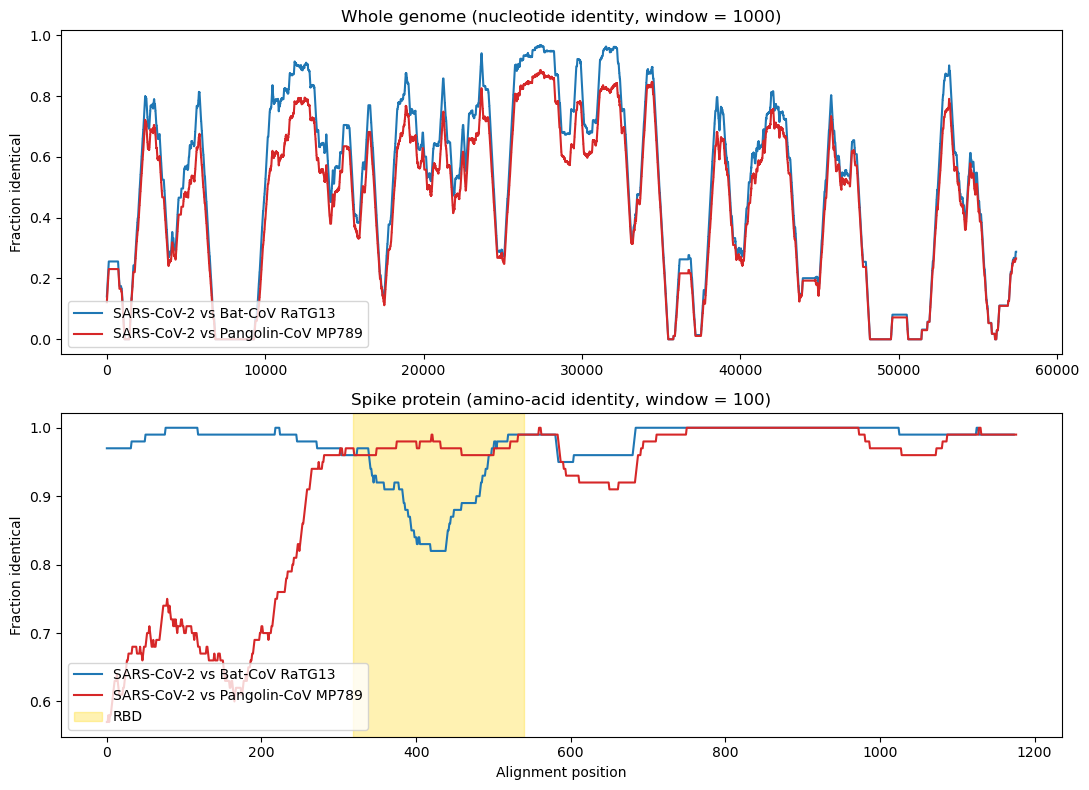

In [70]:
import numpy as np
import matplotlib.pyplot as plt
from Bio import Entrez, SeqIO
from Bio.Align import substitution_matrices

# global alignment (Needleman-Wunsch)
def global_alignment(seq1, seq2, scoring_function):
    n, m = len(seq1), len(seq2)
    scores = np.zeros((n + 1, m + 1), dtype=float)
    traceback = np.zeros((n + 1, m + 1), dtype=int)   # 0 diagonal, 1 up, 2 left
    for i in range(1, n + 1):
        scores[i, 0] = scores[i - 1, 0] + scoring_function(seq1[i - 1], "-")
        traceback[i, 0] = 1
    for j in range(1, m + 1):
        scores[0, j] = scores[0, j - 1] + scoring_function("-", seq2[j - 1])
        traceback[0, j] = 2
    for i in range(1, n + 1):
        for j in range(1, m + 1):
            diagonal = scores[i - 1, j - 1] + scoring_function(seq1[i - 1], seq2[j - 1])
            up = scores[i - 1, j] + scoring_function(seq1[i - 1], "-")
            left = scores[i, j - 1] + scoring_function("-", seq2[j - 1])
            best = max(diagonal, up, left)
            scores[i, j] = best
            traceback[i, j] = 0 if best == diagonal else (1 if best == up else 2)
    a1, a2, i, j = [], [], n, m
    while i > 0 or j > 0:
        if i > 0 and j > 0 and traceback[i, j] == 0:
            a1.append(seq1[i - 1]); a2.append(seq2[j - 1]); i -= 1; j -= 1
        elif i > 0 and (j == 0 or traceback[i, j] == 1):
            a1.append(seq1[i - 1]); a2.append("-"); i -= 1
        else:
            a1.append("-"); a2.append(seq2[j - 1]); j -= 1
    return "".join(reversed(a1)), "".join(reversed(a2)), float(scores[n, m])

# spike proteins from NCBI 
def fetch_spike(acc):
    handle = Entrez.efetch(db="nucleotide", id=acc, rettype="gb", retmode="text")
    record = SeqIO.read(handle, "genbank")
    for f in record.features:
        if f.type == "CDS":
            gene = f.qualifiers.get("gene", [""])[0]
            product = f.qualifiers.get("product", [""])[0].lower()
            if gene == "S" or "spike" in product:
                return str(f.extract(record.seq).translate(to_stop=True))

spike = {name: fetch_spike(acc) for name, acc in accession_codes.items()}
print({k: len(v) for k, v in spike.items()})        # about 1273, 1269, 1270

# the two alignments (human vs bat, human vs pangolin) 
blosum = substitution_matrices.load("BLOSUM62")
def score(a, b):
    return -4 if a == "-" or b == "-" else blosum[a][b]

human = spike["Human-SARS-CoV-2"]
aligned = {}
for other in ["Bat-CoV RaTG13", "Pangolin-CoV MP789"]:
    a_h, a_o, _ = global_alignment(human, spike[other], score)
    aligned[other] = (a_h, a_o)

# sliding-window identity 
def window_identity(a, b, window):
    match = np.array([x == y and x != "-" for x, y in zip(a, b)], float)
    cs = np.concatenate([[0], np.cumsum(match)])
    starts = np.arange(0, len(match) - window + 1)
    return starts, (cs[starts + window] - cs[starts]) / window

def residue_to_column(aligned_human, residue):
    count = 0
    for col, ch in enumerate(aligned_human):
        if ch != "-":
            count += 1
            if count == residue:
                return col

RBD = (319, 541)
colors = {"Bat-CoV RaTG13": "tab:blue", "Pangolin-CoV MP789": "tab:red"}
fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# whole genome (nucleotides, from the supplied genome alignment) 
def read_fasta(path):
    seqs, key = {}, None
    for line in open(path):
        line = line.strip()
        if line.startswith(">"):
            key = line[1:]; seqs[key] = []
        elif key:
            seqs[key].append(line)
    return {k: "".join(v).upper() for k, v in seqs.items()}

g = read_fasta("data/clustal_MSA_coronavirus.fasta")
pick = lambda prefix: [v for k, v in g.items() if k.startswith(prefix)][0]
g_h, g_bat, g_pan = pick("Human-SARS-CoV-2"), pick("BatCoV_RaTG13"), pick("PCoV")
for name, seq in [("Bat-CoV RaTG13", g_bat), ("Pangolin-CoV MP789", g_pan)]:
    x, y = window_identity(g_h, seq, 1000)
    axes[0].plot(x, y, color=colors[name], label=f"SARS-CoV-2 vs {name}")
axes[0].set_title("Whole genome (nucleotide identity, window = 1000)")
axes[0].set_ylabel("Fraction identical")
axes[0].legend(loc="lower left")

# spike (amino acids, window = 100) 
for name, (a_h, a_o) in aligned.items():
    x, y = window_identity(a_h, a_o, 100)
    axes[1].plot(x, y, color=colors[name], label=f"SARS-CoV-2 vs {name}")
a_h = aligned["Bat-CoV RaTG13"][0]
axes[1].axvspan(residue_to_column(a_h, RBD[0]), residue_to_column(a_h, RBD[1]),
                color="gold", alpha=0.3, label="RBD")
axes[1].set_title("Spike protein (amino-acid identity, window = 100)")
axes[1].set_xlabel("Alignment position")
axes[1].set_ylabel("Fraction identical")
axes[1].legend(loc="lower left")

plt.tight_layout()
plt.savefig("recombination.svg")
plt.savefig("recombination.png", dpi=200, bbox_inches="tight")
plt.show()

In [71]:
accession_codes = {
    "Human-SARS-CoV-2": "NC_045512",
    "Bat-CoV RaTG13": "MN996532",
    "Pangolin-CoV MP789": "MT121216",
}

In [72]:
recombination_inside_rbd = """
Which coronavirus is more similar to SARS-CoV-2 inside the RBD and which is more similar outside the RBD?

Inside the RBD (spike residues ~319-541) the pangolin coronavirus MP789 is more similar to SARS-CoV-2 which is about 96-99%
amino-acid identity, while the bat coronavirus RaTG13 is less similar there where its identity dips to about 82%.
Outside the RBD the bat coronavirus RaTG13 is more similar to SARS-CoV-2. About 97-100% identity across the start of the
spike, where the pangolin virus drops to about 60-75%, and about 96-100% after the RBD vs about 91-96% for the pangolin
virus. Across the whole genome, the bat virus is also closer to SARS-CoV-2 than the pangolin virus.

I observed this on the spike plot where in the shaded RBD region the red (pangolin) similarity curve rises above the blue
(bat) curve, whereas everywhere else the blue (bat) curve is equal to or above the red one, so the two curves cross at
the edges of the RBD. This localised switch in which virus is closest, while the bat virus is closest over the rest of
the genome which is also the pattern expected from a recombination event.
"""

In [73]:
recombination_other_regions = """
Looking at your visualisation, are there other regions in the genome (or still in the spike region) that could be due to recombination?

Besides the RBD, there are other dips in similarity for both viruses, mainly in the S1 subunit at the start of the spike and
in a few other parts of the genome where the curves approach or cross each other. These regions could also be recombination
breakpoints. However, there are alternative explanations that do not need recombination. The spike S1 region, including the RBD, binds
the host receptor and is under strong positive selection, so it can evolve faster or converge in unrelated viruses
(convergent evolution to bind the same receptor, ACE2) without any DNA being exchanged. Different mutation rates between
regions, poorly aligned or gappy regions, and mutation saturation also lower the sliding-window identity. Recombination
would need to be confirmed with a phylogenetic test (different tree topologies for different regions), not just from
identity curves.
"""

## Bonus 1: Bootstrap confidence

We performed an alignement, calulated pairwise distances and built a phylogenetic tree. Are we confident in our phylogenetic tree? The answer is, we don't know, because we never estimated the uncertainty of our solution.

In 1985, Joseph Felsenstein wrote an [article](https://pubmed.ncbi.nlm.nih.gov/28561359/) on estimating confidence limits of phylogenetic trees using a non-parametric bootstrap. It stands from the idea of creating bootstrap versions of alignment and building alternative phylogenetic trees. A confidence in a clade is then represented as a proportion of alternative trees that contain the same clade.

To generate a bootstrap version of alignment with length $N$, we sample $N$ alignment positions with replacement. Rearanging sequences accoring to a sequence of sampled indicies give us an alternative alignment. Based on new alignment we calculate the distance and apply neighbor joining algorithm to get an alternative tree.

Here we define a clade equivalence:
*Let $L$ be a set of leaf nodes in a clade from original tree and $L'$ be a set of leaf nodes in a clade from alternative tree. Let $L_1$ and $L_2$ be sets of leaf nodes of both children of a clade, such that $L = L_1 \bigcup L_2$. A clade of an alternative tree is considered the same if and only if $L = L'$ and ( $L_1 \bigcap L_1' = \emptyset\;\land\;L_2 \bigcap L_2'=\emptyset$ or $L_1 \bigcap L_2' = \emptyset\;\land\;L_2 \bigcap L_1'=\emptyset$ ).*

You are now given a Clustal mutliple sequence alignment of spike proteins from the same coronavirses as before. The alignment is store in `data/clustal_MSA_coronavirus_spike.fasta`. Again use Hamming distance for calculating distance and Breda virus as an outgroup.

**Task:** Construct a phylogenetic tree from spike protein MSA and use the bootstrap method for estimating confidence of each clade. Plot the phylogenetic tree and add confidence estimates on the plot.

**a)** Construct 100 alternative trees from bootstraped coronavirus alignments. Make sure you root your trees before estimating confidence.

**b)** Write a function to find a clade from the original tree in an alternative tree.

**c)** Calculate and asign confidence value of a clade to an attribute `Node.confidence`. Note that leaf nodes always have confidence 1.

**d)** Plot the phylogeny tree with confidence estimates using the same plotting function `plot_nj_tree` as in Problem 3. Do not plot confidence of leaf nodes.

Save your plot into `confidence_tree.svg`. Make sure you save the figure using `plt.savefig('confidence_tree.svg')` to ensure the correct format.

**[9 points]**

Then answer the following question:
- How does the phylogenetic tree compare to the one from Problem 3? Which part of the phylogenetic tree are we the least confident in?

Store your answers in the `bootstrap_comparison` variable.


**[1 points]**

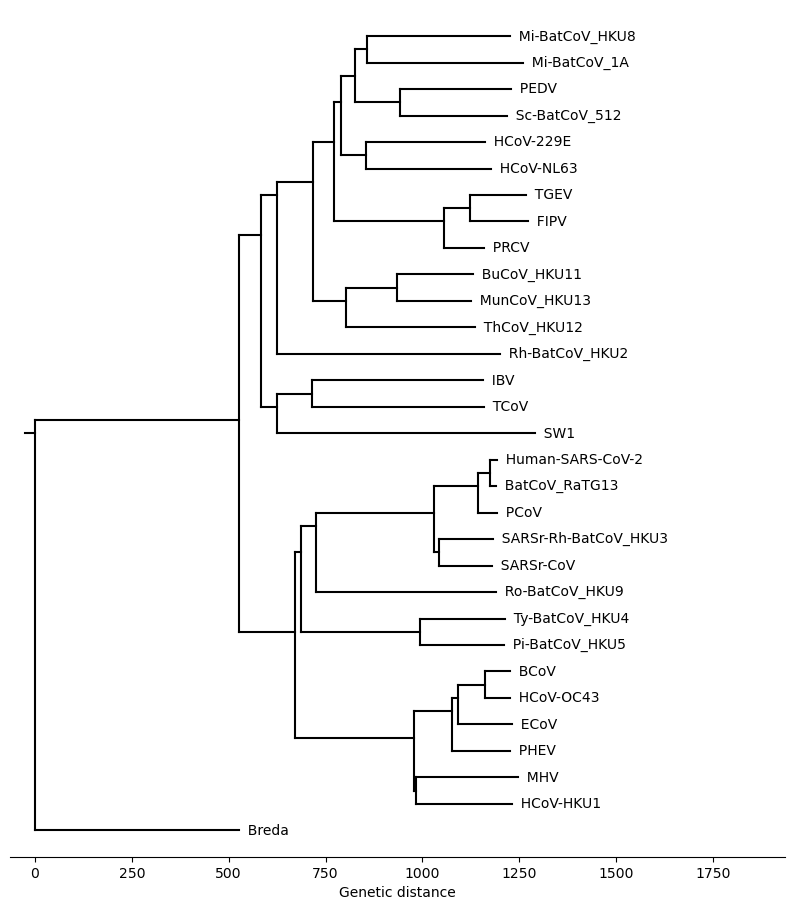

In [75]:
import numpy as np
import matplotlib.pyplot as plt
from helper_functions import neighbor_joining, plot_nj_tree, reroot_tree, sort_children_by_leaves

def read_fasta(path):
    seqs, key = {}, None
    for line in open(path):
        line = line.strip()
        if line.startswith(">"):
            key = line[1:]; seqs[key] = []
        elif key:
            seqs[key].append(line)
    return {k: "".join(v).upper() for k, v in seqs.items()}

def find_node(t, name):
    if t is None: return None
    return t if t.name == name else (find_node(t.left, name) or find_node(t.right, name))

aln = read_fasta("data/clustal_MSA_coronavirus_spike.fasta")
labels = [k.split("|")[0] for k in aln]
arr = np.array([list(s) for s in aln.values()])

def build_rooted_tree(arr):
    """Hamming distance -> neighbor joining -> reroot with Breda."""
    n = arr.shape[0]
    D = np.array([[(arr[i] != arr[j]).sum() for j in range(n)] for i in range(n)], float)
    tree = neighbor_joining(D, labels)
    return reroot_tree(tree, find_node(tree, "Breda"))

# a) 100 bootstrap trees (sample alignment columns with replacement)
rng = np.random.default_rng(0)
original = build_rooted_tree(arr)
boot_trees = []
for _ in range(100):
    cols = rng.integers(0, arr.shape[1], arr.shape[1])
    boot_trees.append(build_rooted_tree(arr[:, cols]))

# b) find a clade of the original tree in an alternative tree
def leaves(node):
    if node.left is None and node.right is None:
        return frozenset([node.name])
    return leaves(node.left) | leaves(node.right)

def all_clades(tree):
    """Every internal node as (leaf set L, {L1, L2})."""
    out = []
    def rec(node):
        if node.left is None:
            return
        out.append((leaves(node), {leaves(node.left), leaves(node.right)}))
        rec(node.left); rec(node.right)
    rec(tree)
    return out

def clade_in_tree(clade, alt_tree):
    """True if alt_tree has a clade with the same leaf set L and the same split L1/L2."""
    L, split = clade
    return any(L == L2 and split == split2 for L2, split2 in all_clades(alt_tree))

# c) confidence = proportion of bootstrap trees containing the clade
def assign_confidence(node):
    if node.left is None:
        node.confidence = 1.0                       # leaves always have confidence 1
        return
    clade = (leaves(node), {leaves(node.left), leaves(node.right)})
    node.confidence = sum(clade_in_tree(clade, t) for t in boot_trees) / len(boot_trees)
    assign_confidence(node.left); assign_confidence(node.right)

assign_confidence(original)
sort_children_by_leaves(original)

# d) plot with confidence on internal nodes
fig, ax = plt.subplots(figsize=(10, 11))
plot_nj_tree(original, ax=ax, show_confidence=True)
plt.savefig("confidence_tree.svg", bbox_inches="tight")
plt.show()

In [74]:
bootstrap_comparison = """
How does the phylogenetic tree compare to the one from Problem 3? Which part of the phylogenetic tree are we the least confident in?

The spike-protein tree has the same main structure as the Problem 3 tree: the four coronavirus groups form their own
clades and the SARS-CoV-2 / bat RaTG13 / pangolin viruses sit together in the Betacoronavirus group with the SARS-related
viruses. Most clades have high bootstrap confidence (close to 1.0), so those parts of the tree are reliable. We are least
confident about the group of betacoronaviruses containing HCoV-HKU1, MHV, BCoV, ECoV, PHEV and HCoV-OC43. The clade
joining HKU1 with MHV has a confidence of only about 0.53, the six-virus group containing them also about 0.53, and the
BCoV/ECoV/PHEV/OC43 clades about 0.68. These are old, divergentt splits where the spike alignment carries less
phylogenetic signal which results in resampled alignment columns often changing how those viruses are arranged.

"""